# 📙 Notebook 10 — Dynamic Monte Carlo Case Study: Choosing the Control Volume
| | |
|---|---|
| ⏱ Time | ~25 min (simulations ≈ 1 min) |
| 🧭 Type | **dynamic Monte Carlo** — Gillespie's method, batch reactor |
| 🎯 Goal | reproduce the control-volume study: event log (**Table 4.2**), polymerization times and dead chains (**Tables 4.2–4.7**), initiator check (**Table 4.9**), w-CLDs (**Figures 4.10–4.11**) |
| 📖 Book | Sec. 4.5–4.6 · Table 4.1 · Algorithm 4.3 |

**The question:** a dynamic simulation follows every molecule in a small **control volume** `V`. How small can `V` be before the results stop representing a bulk reactor? This notebook is about the code; for the discussion, see *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture*.

**System:** batch free-radical polymerization of styrene at 90 °C with the mechanism and rate constants of Case Study 3.1 (Notebook 8): `[M]₀ = 8 mol/L`, `[I]₀ = 0.92 mmol/L`, stop at conversion `X = 0.1`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from numba import njit
plt.rcParams.update({"figure.figsize": (6, 3.8), "axes.grid": True, "grid.alpha": 0.3})

## 1 · Parameters
Rate constants from Table 3.2 (min⁻¹, L/(mol·min)). The book does not list `k_i` separately; we use fast initiation, `k_i = k_p`, which reproduces the propensities in the first rows of the book's event logs (e.g. `R_tot ≈ 4.455 × 10⁵ min⁻¹` right after the first decomposition).

In [2]:
NA = 6.022e23
R_gas, T = 1.987, 90 + 273.15
arrh = lambda A, E: A * np.exp(-E / (R_gas * T))
kd  = arrh(1.6945e15, 31500)
kp  = arrh(1.302e9,   7759)
ktM = arrh(5.14e9,   15230)
ktc = arrh(4.92e11,   3470)
ki  = kp
f, M0, I0, X_target = 0.7, 8.0, 0.92e-3, 0.1

P0 = np.sqrt(f * kd * I0 / ktc)                     # Eq. 4.66
print(f"[P]0 = {P0:.4e} mol/L   (book: 5.468e-09)")

[P]0 = 5.4679e-09 mol/L   (book: 5.468e-09)


## 2 · Gillespie's method in code (Algorithm 4.3 + Table 4.1)
**Microscopic rate constants** (Table 4.1): `k_d^MC = k_d`, `k_i^MC = k_i/(V·N_A)`, `k_p^MC = k_p/(V·N_A)`, `k_tM^MC = k_tM/(V·N_A)`, `k_tc^MC = 2k_tc/(V·N_A)`.

**Propensities:** `R_d = k_d^MC n_I`, `R_i = k_i^MC n_M n_R`, `R_p = k_p^MC n_M n_P`, `R_tM = k_tM^MC n_M n_P`, `R_tc = k_tc^MC n_P(n_P − 1)/4`.

**Data structures:**
- `P`: array with the length of every polymer radical; the first `nP` entries are in use. Picking a random radical = picking a random index. Removing one = moving the last radical into its place (O(1)).
- `D`: counting vector of dead chains, `D[n]` = number of dead chains of length `n` (as in Case Study 3.1).
- `log`: the first events, to build an event log like Table 4.2.

**Speed trick:** the reactions are tested in the order *propagation first*. Since propagation is selected in >99 % of the steps, the roulette wheel usually stops at the first comparison. The order of the reaction channels doesn't change the statistics, only the speed. The function is compiled with Numba (`@njit`), as in Notebooks 8–9.

In [3]:
EVENTS = ["Initiator decomposition", "Chain initiation", "Propagation", "Transfer to monomer", "Combination"]

@njit
def gillespie_batch(V, ktc_on, seed, n_log):
    np.random.seed(seed)
    VNA = V * NA
    kdMC, kiMC, kpMC, ktMMC = kd, ki/VNA, kp/VNA, ktM/VNA        # Table 4.1
    ktcMC = 2*ktc/VNA if ktc_on else 0.0
    nM0 = int(round(M0*VNA)); nM = nM0                          # Algorithm 4.3, lines 2–3
    nI0 = int(round(I0*VNA)); nI = nI0; nR = 0
    P = np.zeros(2*nI0 + 10, np.int64); nP = 0                  # polymer radical lengths
    n_max = min(int(nM0*X_target) + 10, 3_000_000)
    D = np.zeros(n_max, np.int64); nD = 0                       # dead chains (counting vector)
    t = 0.0; ev = 0
    log = np.zeros((n_log, 10))
    while True:
        # propensities (line 7)
        Rp  = kpMC*nM*nP
        Rd  = kdMC*nI
        Ri  = kiMC*nR*nM
        RtM = ktMMC*nM*nP
        Rtc = ktcMC*nP*(nP - 1)/4.0
        Rtot = Rp + Rd + Ri + RtM + Rtc
        if Rtot <= 0.0 or (nM0 - nM)/nM0 >= X_target:          # stop: no reactions left, or target reached
            break
        # select reaction (lines 8–9)
        r = np.random.random()*Rtot
        if r < Rp:                                              # propagation
            j = np.random.randint(nP); P[j] += 1; nM -= 1; e = 2
        elif r < Rp + Rd:                                       # initiator decomposition
            nI -= 1
            if np.random.random() <= f: nR += 2
            e = 0
        elif r < Rp + Rd + Ri:                                  # chain initiation
            nR -= 1; nM -= 1; P[nP] = 1; nP += 1; e = 1
        elif r < Rp + Rd + Ri + RtM:                            # transfer to monomer
            j = np.random.randint(nP); D[min(P[j], n_max-1)] += 1; nD += 1
            P[j] = 1; nM -= 1; e = 3
        else:                                                   # combination
            j = np.random.randint(nP); a = P[j]; nP -= 1; P[j] = P[nP]
            j = np.random.randint(nP); b = P[j]; nP -= 1; P[j] = P[nP]
            D[min(a + b, n_max-1)] += 1; nD += 1; e = 4
        # advance the clock (lines 38–40)
        dt = np.log(1.0/np.random.random())/Rtot
        t += dt; ev += 1
        if ev <= n_log:                                         # keep the first events for the event log
            row = log[ev-1]
            row[0] = ev; row[1] = t; row[2] = dt; row[3] = Rtot; row[4] = e
            row[5] = nM; row[6] = nI; row[7] = nR; row[8] = nP; row[9] = nD
    final = np.zeros(10)
    final[0] = ev; final[1] = t; final[2] = Rtot; final[3] = nM; final[4] = nI
    final[5] = nR; final[6] = nP; final[7] = nD; final[8] = nM0; final[9] = nI0
    return final, D, log

## 3 · Event log for V = 10⁻¹⁷ L (compare with Table 4.2)
With so few molecules, every event is visible. Note the first steps: nothing can happen until the initiator decomposes; then the total propensity jumps by five orders of magnitude.

In [4]:
def event_log(V, n_log=8, seed=1):
    final, D, log = gillespie_batch(V, True, seed, n_log)
    df = pd.DataFrame(log, columns=["Reaction", "Time (min)", "Δt (min)", "R_tot (1/min)", "Event",
                                    "n_M", "n_I", "n_R", "n_P", "n_D"])
    df["Event"] = [EVENTS[int(e)] for e in df["Event"]]
    ev, t, Rtot, nM, nI, nR, nP, nD, nM0, nI0 = final
    df.loc[len(df)] = [ev, t, np.nan, Rtot, "Final state", nM, nI, nR, nP, nD]
    for c in ["Reaction", "n_M", "n_I", "n_R", "n_P", "n_D"]: df[c] = df[c].astype(int)
    print(f"n_M0 = {int(nM0):,}   n_I0 = {int(nI0):,}   final conversion X = {(nM0 - nM)/nM0:.4f}")
    return df

event_log(1e-17).style.format({"Time (min)": "{:.6f}", "Δt (min)": "{:.6f}", "R_tot (1/min)": "{:.5e}"}, na_rep="")

n_M0 = 48,176,000   n_I0 = 5,540   final conversion X = 0.0524


,Reaction,Time (min),Δt (min),R_tot (1/min),Event,n_M,n_I,n_R,n_P,n_D
0,1,8.793244,8.793244,1.03216e+00,Initiator decomposition,48176000,5539,0,0,0
1,2,11.101728,2.308484,1.03197e+00,Initiator decomposition,48176000,5538,2,0,0
2,3,11.101730,0.000002,4.45500e+05,Chain initiation,48175999,5538,1,1,0
3,4,11.101731,0.000001,4.45528e+05,Propagation,48175998,5538,1,1,0
4,5,11.101732,0.000001,4.45528e+05,Propagation,48175997,5538,1,1,0
5,6,11.101733,0.000000,4.45528e+05,Propagation,48175996,5538,1,1,0
6,7,11.101733,0.000001,4.45528e+05,Propagation,48175995,5538,1,1,0
7,8,11.101735,0.000001,4.45528e+05,Propagation,48175994,5538,1,1,0
8,2534968,63259.243029,,0.00000e+00,Final state,45650366,0,0,0,4115


The run stops **before** `X = 0.1`: all the initiator was used up. Expected number of radicals in this volume: `n_P = V·[P]·N_A ≈ 0.03` — far below 1. Each new pair of radicals is killed almost immediately by combination, so the simulation burns through the initiator (book Sec. 4.6.1).

## 4 · Scanning the control volume
For each `V`, we record: expected `n_P`, final time, conversion reached, number of dead chains `n_D`, and the initiator check `[I]_MC` vs `[I]_det = [I]₀·exp(−k_d t)` (Table 4.9). The largest volume takes the longest (~30 s).

In [5]:
volumes = [1e-17, 2e-17, 5e-17, 1e-16, 5e-16, 1e-15]
book_t  = {1e-17: "57,241 (stalled)", 2e-17: "19,931", 5e-17: "2,586", 1e-16: "1,280", 5e-16: "508.3", 1e-15: "501.9"}
book_nD = {1e-17: 4196, 2e-17: 8723, 5e-17: 10667, 1e-16: 14211, 5e-16: 48180, 1e-15: 95231}

gillespie_batch(1e-18, True, 0, 1)                    # compile once (a few seconds)
rows, cld = [], {}
for V in volumes:
    t0 = time.time()
    final, D, _ = gillespie_batch(V, True, 1, 1)
    ev, t, Rtot, nM, nI, nR, nP, nD, nM0, nI0 = final
    cld[V] = D
    rows.append({"V (L)": f"{V:.0e}", "expected n_P": V*P0*NA, "events": int(ev), "X reached": (nM0 - nM)/nM0,
                 "t_final (min)": t, "book t_final (min)": book_t[V], "n_D": int(nD), "book n_D": book_nD[V],
                 "[I]_MC (mol/L)": nI/(V*NA), "[I]_det (mol/L)": I0*np.exp(-kd*t), "CPU (s)": time.time() - t0})
table = pd.DataFrame(rows)
table.style.format({"expected n_P": "{:.3f}", "events": "{:,}", "X reached": "{:.4f}", "t_final (min)": "{:,.1f}",
                    "n_D": "{:,}", "book n_D": "{:,}", "[I]_MC (mol/L)": "{:.3e}", "[I]_det (mol/L)": "{:.3e}", "CPU (s)": "{:.1f}"})

,V (L),expected n_P,events,X reached,t_final (min),book t_final (min),n_D,book n_D,[I]_MC (mol/L),[I]_det (mol/L),CPU (s)
0,1e-17,0.033,"2,534,968",0.0524,"63,259.2","57,241 (stalled)","4,115","4,196",0.000e+00,7.003e-09,0.1
1,2e-17,0.066,"9,653,679",0.1000,"21,998.1","19,931","8,782","8,723",1.752e-05,1.527e-05,0.5
2,5e-17,0.165,"24,107,085",0.1000,"2,825.9","2,586","10,838","10,667",5.469e-04,5.434e-04,1.2
3,1e-16,0.329,"48,195,513",0.1000,"1,268.5","1,280","14,201","14,211",7.298e-04,7.264e-04,2.4
4,5e-16,1.646,"240,922,741",0.1000,510.7,508.3,"47,822","48,180",8.366e-04,8.365e-04,11.8
5,1e-15,3.293,"481,844,232",0.1000,500.0,501.9,"95,155","95,231",8.378e-04,8.382e-04,24.2


**How to read the table**
- `V = 10⁻¹⁷ L` never reaches `X = 0.1`; its `[I]_MC` drops to zero long before `[I]_det` does.
- The polymerization time keeps changing until `V ≥ 5 × 10⁻¹⁶ L` (`n_P` ≳ 1.6), then settles near **500 min**.
- `n_D` grows linearly with `V` once `V` is large enough — as it should for an extensive quantity.
- Individual runs are stochastic: small volumes scatter more from run to run (try another `seed`).

## 5 · Figures 4.10 and 4.11: w-CLDs vs. control volume
Bin size `Δn = 100`, as in the book.

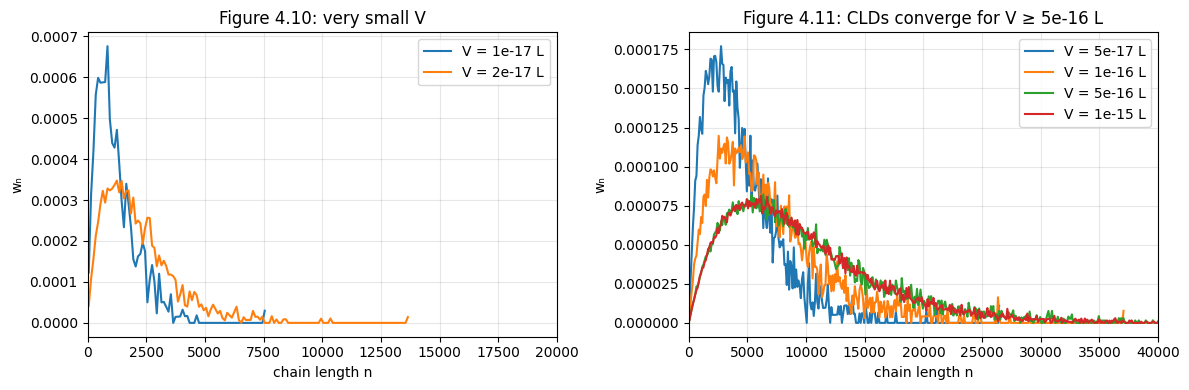

In [6]:
def wcld(D, dn=100):
    n = np.arange(len(D))
    last = np.nonzero(D)[0].max()
    edges = np.arange(1, last + dn, dn)
    mass, _ = np.histogram(n, bins=edges, weights=n*D)
    return 0.5*(edges[1:] + edges[:-1]), mass / mass.sum() / dn

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for V in [1e-17, 2e-17]:
    x, w = wcld(cld[V]); ax[0].plot(x, w, label=f"V = {V:.0e} L")
ax[0].set_title("Figure 4.10: very small V"); ax[0].set_xlim(0, 20_000)
for V in [5e-17, 1e-16, 5e-16, 1e-15]:
    x, w = wcld(cld[V]); ax[1].plot(x, w, label=f"V = {V:.0e} L")
ax[1].set_title("Figure 4.11: CLDs converge for V ≥ 5e-16 L"); ax[1].set_xlim(0, 40_000)
for a in ax: a.set_xlabel("chain length n"); a.set_ylabel("wₙ"); a.legend()
plt.tight_layout(); plt.show()

## ✅ What the code taught us
- In dynamic Monte Carlo, the **control volume is a model parameter**: too small and the simulation becomes a "nanoreactor" with too few radicals.
- Practical rule (book Sec. 4.6): choose `V` so that `n_P = V·[P]·N_A` is well above 1 — preferably tens.
- Checks: the CLD, the event-based polymerization time, and the initiator decay should all become **independent of V**. The initiator check is necessary but not sufficient.
- The book shows full convergence at `V ≥ 10⁻¹⁴ L` (~5 × 10⁹ events per run — too long for a quick notebook; see Table 4.8).

### 🧪 Try it yourself
1. Re-run the scan with `seed = 2`. Which volumes change the most?
2. Add `2e-15` to `volumes` (~1 min). Does `t_final` move?
3. Store `n_P` every 10⁶ events for `V = 1e-16` and `1e-15` and plot it against time. Where do you see the "nanoreactor" behaviour?
4. Pass `ktc_on=False` to remove combination (book Sec. 4.6.3). What happens to `n_P` and to the final conversion in the smallest volume?